In [37]:
### 0) Setup and Imports

import pandas as pd
import numpy as np
import os
import geopandas as gpd
from shapely.geometry import Point, box, LineString
from shapely.ops import linemerge
import matplotlib.pyplot as plt


In [38]:
### 1) Import CSV Ecohydro Data
# currently desired data is in complete_data.csv

# Keep spatial data in feet for HWRC stakeholders:
complete_data_25 = pd.read_csv("data/25_ecohydroData.csv")
print(complete_data_25.columns)
complete_data_26 = pd.read_csv("data/26_ecohydroData.csv")
print(complete_data_26.columns)

# Combine the 2 years of data into one csv by matching columns and appending the data
complete_data = pd.concat([complete_data_25, complete_data_26], ignore_index=True)
print("Total points in complete_data from 2025: ", len(complete_data_25))
print("Total points in complete_data from 2026: ", len(complete_data_26))
print("Total points in complete_data: ", len(complete_data))

Index(['Collection Date', 'Collection Time', 'Northing', 'Easting',
       'Elevation', 'Longitude', 'Latitude', 'Global_ID_Eco', 'Type',
       'Transect ID', 'Section', 'Measurement Point ID', 'Reading Number',
       'Total water depth', 'Depth', 'Actual depth', 'Velocity', 'Velocity 2',
       'Point Notes', 'SMB Presence', 'Bank Measurement Began',
       'Investigators'],
      dtype='object')
Index(['Collection Date', 'Collection Time', 'Northing', 'Easting',
       'Elevation', 'Longitude', 'Latitude', 'Global_ID_Eco', 'Type',
       'Transect ID', 'Section', 'Measurement Point ID', 'Reading Number',
       'Total water depth', 'Depth', 'Velocity', 'Depth 2', 'Velocity 2',
       'Point Notes', 'SMB Presence', 'Bank Measurement Began',
       'Investigators'],
      dtype='object')
Total points in complete_data from 2025:  1195
Total points in complete_data from 2026:  2363
Total points in complete_data:  3558


In [39]:
### Sort the data into separate csvs based on their northing column value
# currently desired data is in complete_data_{Section} df

# Assign "Section" based on northing value that was made based on observation of data
# One transect at North Territorial is removed; it's too far North of Middle section
complete_data.loc[complete_data['Northing'] > 340000, 'Section'] = 'Upper'
complete_data.loc[
    (complete_data['Northing'] <= 323000) & (complete_data['Northing'] >= 280000), 'Section'
] = 'Middle'
complete_data.loc[complete_data['Northing'] < 255000, 'Section'] = 'Lower'

# Treat blank (NaN or empty string) values in the Section column as "Middle"
complete_data['Section'] = complete_data['Section'].replace('', np.nan)
complete_data['Section'] = complete_data['Section'].fillna('Middle')

# Create a separate DataFrame for each section
complete_data_Upper = complete_data[complete_data['Section'] == 'Upper'].copy()
complete_data_Middle = complete_data[complete_data['Section'] == 'Middle'].copy()
complete_data_Lower = complete_data[complete_data['Section'] == 'Lower'].copy()

print(f"Rows in complete_data_Upper.csv: {len(complete_data_Upper)}")
print(f"Rows in complete_data_Middle.csv: {len(complete_data_Middle)}")
print(f"Rows in complete_data_Lower.csv: {len(complete_data_Lower)}")

Rows in complete_data_Upper.csv: 1168
Rows in complete_data_Middle.csv: 1703
Rows in complete_data_Lower.csv: 687


In [40]:
### 2) Import Upstream Depth FOR EACH SECTION (next 2 cells as well)
# currently desired data is in complete_data_{Section} df

# 2a) Middle Section

# Read in the depth
depth_data_mm_25 = pd.read_csv('data/25_depthSensorData_Middle.csv', skiprows=3)
depth_data_mm_26 = pd.read_csv('data/26_depthSensorData_Middle.csv', skiprows=3)

# Combine the 2 years of data into one csv by appending the csvs
depth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)

# Convert datetime columns to pandas datetime and set as index for resampling
depth_data_mm['_time'] = pd.to_datetime(depth_data_mm['_time'])
depth_data_mm = depth_data_mm.set_index('_time')

# Aggregate depth data
depth_interval_minutes = 300
depth_agg = depth_data_mm['_value'].resample(f'{depth_interval_minutes}min').median()
print('Depth resampling successful')

# Remove NaN values from aggregation
depth_agg = depth_agg.dropna()
#print(f'Size of depth_agg: {depth_agg.shape}')

# Depth outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
depth_mean = depth_agg.mean()
depth_std = depth_agg.std()
depth_mask = np.abs(depth_agg - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg[depth_mask]

# Convert depth data from mm to feet (both years already combined above)
# manual inputs are from field observations to convert the sensor output into elevation values
depth_agg_final = ((7313.2 - depth_agg_trimmed) * 0.00328084).sort_index()
print(f'Depth series: {len(depth_agg_final)} points '
      f'({depth_agg_final.index.min().date()} to {depth_agg_final.index.max().date()})')

# Convert Collection Date to pandas datetime
complete_data_Middle['Collection Date'] = pd.to_datetime(
    complete_data_Middle['Collection Date'], format='mixed', dayfirst=False
)

# Extract date only (without time) for matching since trend timescale is daily
complete_data_Middle['Date'] = complete_data_Middle['Collection Date'].dt.date

# Create aggregated daily averages for depth data
# The index is already datetime, so we can convert to date and group
depth_daily_Middle = depth_agg_final.groupby(depth_agg_final.index.date).mean().to_dict()

# Create new columns initialized with NaN
complete_data_Middle['upstream_depth'] = np.nan

# Match and fill data based on date only
for idx, row in complete_data_Middle.iterrows():
    obs_date = row['Date']
    
    # Find matching depth measurement for this date
    if obs_date in depth_daily_Middle:
        complete_data_Middle.at[idx, 'upstream_depth'] = depth_daily_Middle[obs_date]

# Clean up temporary Date column since matching is done
complete_data_Middle = complete_data_Middle.drop(columns=['Date'])

# Print summary of matched data points
print("\nData matching summary:")   
print(f"Total points in complete_data_Middle: {len(complete_data_Middle)}")
print(f"Points with upstream depth data: {complete_data_Middle['upstream_depth'].notna().sum()}")

Depth resampling successful
Depth series: 1288 points (2025-05-30 to 2026-09-01)

Data matching summary:
Total points in complete_data_Middle: 1703
Points with upstream depth data: 1691


In [41]:
'''
# 2b) Upper Section
# currently desired data is in complete_data_{Section} df

# Read in the depth
depth_data_mm_26 = pd.read_csv('data/26_depthSensorData_Upper.csv', skiprows=3)

# Combine the 2 years of data into one csv by appending the csvs
depth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)

# Convert datetime columns to pandas datetime and set as index for resampling
depth_data_mm['_time'] = pd.to_datetime(depth_data_mm['_time'])
depth_data_mm = depth_data_mm.set_index('_time')

# Aggregate depth data
depth_interval_minutes = 300
depth_agg = depth_data_mm['_value'].resample(f'{depth_interval_minutes}min').median()
print('Depth resampling successful')

# Remove NaN values from aggregation
depth_agg = depth_agg.dropna()
print(f'Size of depth_agg: {depth_agg.shape}')

# Depth outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
depth_mean = depth_agg.mean()
depth_std = depth_agg.std()
depth_mask = np.abs(depth_agg - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg[depth_mask]

# Convert depth data from mm to feet (both years already combined above)
depth_agg_final = ((7313.2 - depth_agg_trimmed) * 0.00328084).sort_index()  ### FINAL
print(f'Depth series: {len(depth_agg_final)} points '
      f'({depth_agg_final.index.min().date()} to {depth_agg_final.index.max().date()})')

# Convert Collection Date to pandas datetime
# format='mixed' parses each value individually, handling native Excel datetimes,
# M/D/YYYY text dates (e.g. "6/6/2026"), and dates with times (e.g. "6/6/2025 16:00")
# dayfirst=False ensures M/D/YYYY (month-first) interpretation
complete_data_Upper['Collection Date'] = pd.to_datetime(
    complete_data_Upper['Collection Date'], format='mixed', dayfirst=False
)

# Extract date only (without time) for matching
# Note: depth_agg_final already have DatetimeIndex
complete_data_Upper['Date'] = complete_data_Upper['Collection Date'].dt.date

# Create aggregated daily averages for depth data
# The index is already datetime, so we can convert to date and group
# (Upper-specific name so each section keeps its own daily depth lookup)
depth_daily_Upper = depth_agg_final.groupby(depth_agg_final.index.date).mean().to_dict()

# Create new columns initialized with NaN
complete_data_Upper['upstream_depth'] = np.nan

# Match and fill data based on date only
for idx, row in complete_data_Upper.iterrows():
    obs_date = row['Date']
    
    # Find matching depth measurement for this date
    if obs_date in depth_daily_Upper:
        complete_data_Upper.at[idx, 'upstream_depth'] = depth_daily_Upper[obs_date]

# Clean up temporary Date column
complete_data_Upper = complete_data_Upper.drop(columns=['Date'])

# Print summary of matched data points
print("\nData matching summary:")   
print(f"Total points in complete_data_Upper: {len(complete_data_Upper)}")
print(f"Points with upstream depth data: {complete_data_Upper['upstream_depth'].notna().sum()}")

'''

'\n# 2b) Upper Section\n# currently desired data is in complete_data_{Section} df\n\n# Read in the depth\ndepth_data_mm_26 = pd.read_csv(\'data/26_depthSensorData_Upper.csv\', skiprows=3)\n\n# Combine the 2 years of data into one csv by appending the csvs\ndepth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)\n\n# Convert datetime columns to pandas datetime and set as index for resampling\ndepth_data_mm[\'_time\'] = pd.to_datetime(depth_data_mm[\'_time\'])\ndepth_data_mm = depth_data_mm.set_index(\'_time\')\n\n# Aggregate depth data\ndepth_interval_minutes = 300\ndepth_agg = depth_data_mm[\'_value\'].resample(f\'{depth_interval_minutes}min\').median()\nprint(\'Depth resampling successful\')\n\n# Remove NaN values from aggregation\ndepth_agg = depth_agg.dropna()\nprint(f\'Size of depth_agg: {depth_agg.shape}\')\n\n# Depth outlier trimming\noutlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)\ndepth_mean = depth_ag

In [42]:
'''
# 2c) Lower Section
# currently desired data is in complete_data_{Section} df

# Read in the depth
depth_data_mm_26 = pd.read_csv('data/26_depthSensorData_Lower.csv', skiprows=3)

# Combine the 2 years of data into one csv by appending the csvs
depth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)

# Convert datetime columns to pandas datetime and set as index for resampling
depth_data_mm['_time'] = pd.to_datetime(depth_data_mm['_time'])
depth_data_mm = depth_data_mm.set_index('_time')

# Aggregate depth data
depth_interval_minutes = 300
depth_agg = depth_data_mm['_value'].resample(f'{depth_interval_minutes}min').median()
print('Depth resampling successful')

# Remove NaN values from aggregation
depth_agg = depth_agg.dropna()
print(f'Size of depth_agg: {depth_agg.shape}')

# Depth outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
depth_mean = depth_agg.mean()
depth_std = depth_agg.std()
depth_mask = np.abs(depth_agg - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg[depth_mask]

# Convert depth data from mm to feet (both years already combined above)
depth_agg_final = ((7313.2 - depth_agg_trimmed) * 0.00328084).sort_index()  ### FINAL
print(f'Depth series: {len(depth_agg_final)} points '
      f'({depth_agg_final.index.min().date()} to {depth_agg_final.index.max().date()})')

# Convert Collection Date to pandas datetime
# format='mixed' parses each value individually, handling native Excel datetimes,
# M/D/YYYY text dates (e.g. "6/6/2026"), and dates with times (e.g. "6/6/2025 16:00")
# dayfirst=False ensures M/D/YYYY (month-first) interpretation
complete_data_Lower['Collection Date'] = pd.to_datetime(
    complete_data_Lower['Collection Date'], format='mixed', dayfirst=False
)

# Extract date only (without time) for matching
# Note: depth_agg_final already have DatetimeIndex
complete_data_Lower['Date'] = complete_data_Lower['Collection Date'].dt.date

# Create aggregated daily averages for depth data
# The index is already datetime, so we can convert to date and group
# (Lower-specific name so each section keeps its own daily depth lookup)
depth_daily_Lower = depth_agg_final.groupby(depth_agg_final.index.date).mean().to_dict()

# Create new columns initialized with NaN
complete_data_Lower['upstream_depth'] = np.nan

# Match and fill data based on date only
for idx, row in complete_data_Lower.iterrows():
    obs_date = row['Date']
    
    # Find matching depth measurement for this date
    if obs_date in depth_daily_Lower:
        complete_data_Lower.at[idx, 'upstream_depth'] = depth_daily_Lower[obs_date]

# Clean up temporary Date column
complete_data_Lower = complete_data_Lower.drop(columns=['Date'])

# Print summary of matched data points
print("\nData matching summary:")   
print(f"Total points in complete_data_Lower: {len(complete_data_Lower)}")
print(f"Points with upstream depth data: {complete_data_Lower['upstream_depth'].notna().sum()}")

'''

'\n# 2c) Lower Section\n# currently desired data is in complete_data_{Section} df\n\n# Read in the depth\ndepth_data_mm_26 = pd.read_csv(\'data/26_depthSensorData_Lower.csv\', skiprows=3)\n\n# Combine the 2 years of data into one csv by appending the csvs\ndepth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)\n\n# Convert datetime columns to pandas datetime and set as index for resampling\ndepth_data_mm[\'_time\'] = pd.to_datetime(depth_data_mm[\'_time\'])\ndepth_data_mm = depth_data_mm.set_index(\'_time\')\n\n# Aggregate depth data\ndepth_interval_minutes = 300\ndepth_agg = depth_data_mm[\'_value\'].resample(f\'{depth_interval_minutes}min\').median()\nprint(\'Depth resampling successful\')\n\n# Remove NaN values from aggregation\ndepth_agg = depth_agg.dropna()\nprint(f\'Size of depth_agg: {depth_agg.shape}\')\n\n# Depth outlier trimming\noutlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)\ndepth_mean = depth_ag

In [43]:
### 3) ADCP Velocity upload and merge
# currently desired data is in complete_data_{Section} df

# Read in the velocity
sontek_data = pd.read_csv('data/25_ADCPData.csv', skiprows=3)

# Convert datetime columns to pandas datetime and set as index for resampling
sontek_data['_time'] = pd.to_datetime(sontek_data['_time'])
sontek_data = sontek_data.set_index('_time')

# Aggregate sontek velocity data
sontek_interval_minutes = 300
sontek_agg = sontek_data['_value'].resample(f'{sontek_interval_minutes}min').median()
print('Sontek resampling successful')

# Remove NaN values from aggregation
sontek_agg = sontek_agg.dropna()
#print(f'Aggregated data shape: {sontek_agg.shape}')

# Sontek outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
sontek_mean = sontek_agg.mean()
sontek_std = sontek_agg.std()
sontek_mask = np.abs(sontek_agg - sontek_mean) <= outlier_std_threshold * sontek_std
sontek_agg_final = sontek_agg[sontek_mask]

# Create a DataFrame from the aggregated sontek velocity data
# The ADCP sensor is located in the Middle section, so tag it accordingly
sontek_df = pd.DataFrame({
    'Collection Date': sontek_agg_final.index,   # _time from velocity data
    'Velocity': sontek_agg_final.values,         # aggregated velocity values
    'Depth': 1,                                  # set Depth to 1 for all velocity points
    'Northing': 319995.5,                        # constant Northing for sontek location
    'Easting': 13244857,                         # constant Easting for sontek location
    'Type': 'Sontek',                            # add Type column for plotting model dependencies
    'Section': 'Middle'                          # ADCP data belongs to the Middle section
})

# Match upstream_depth for sontek data based on date (using the Middle section's daily depths)
sontek_df['upstream_depth'] = sontek_df['Collection Date'].apply(
    lambda dt: depth_daily_Middle.get(dt.date(), np.nan)
)
#print(f"Sontek points with upstream_depth matched: {sontek_df['upstream_depth'].notna().sum()} / {len(sontek_df)}")

# Append the sontek velocity data to complete_data_Middle
complete_data_Middle = pd.concat([complete_data_Middle, sontek_df], ignore_index=True)

# Print summary of added data points
print(f"\nSontek velocity data appended to complete_data_Middle")
print(f"  Points added: {len(sontek_df)}")
print(f"  New total rows in complete_data_Middle: {len(complete_data_Middle)}")

Sontek resampling successful

Sontek velocity data appended to complete_data_Middle
  Points added: 475
  New total rows in complete_data_Middle: 2178


In [44]:
### 4) Data Trimming Based on Depth of Measurement and Velocity Magnitude
# only measurement depths below 1 foot will be considered
# measurement depth is varaible "Depth"
# currently desired data is in complete_data_Section df

# Print initial size
initial_count_Middle = len(complete_data_Middle)
initial_count_Upper = len(complete_data_Upper)
initial_count_Lower = len(complete_data_Lower)

print(f"Initial counts:")
print(f"  Middle: {initial_count_Middle}")
print(f"  Upper: {initial_count_Upper}")
print(f"  Lower: {initial_count_Lower}")

# Trim based on depth >= 1
depth_trimmed_Middle = complete_data_Middle[complete_data_Middle['Depth'] <= 1]
depth_trimmed_Upper = complete_data_Upper[complete_data_Upper['Depth'] <= 1]
depth_trimmed_Lower = complete_data_Lower[complete_data_Lower['Depth'] <= 1]

depth_trimmed_count_Middle = len(depth_trimmed_Middle)
depth_trimmed_count_Upper = len(depth_trimmed_Upper)
depth_trimmed_count_Lower = len(depth_trimmed_Lower)

# Trim based on velocity >= 0
vel_trimmed_Middle = depth_trimmed_Middle[depth_trimmed_Middle['Velocity'] >= 0]
vel_trimmed_Upper = depth_trimmed_Upper[depth_trimmed_Upper['Velocity'] >= 0]
vel_trimmed_Lower = depth_trimmed_Lower[depth_trimmed_Lower['Velocity'] >= 0]

vel_trimmed_count_Middle = len(vel_trimmed_Middle)
vel_trimmed_count_Upper = len(vel_trimmed_Upper)
vel_trimmed_count_Lower = len(vel_trimmed_Lower)

print(f"Middle: Rows after velocity >= 0 filter: {vel_trimmed_count_Middle} (total removed: {initial_count_Middle - vel_trimmed_count_Middle})")
print(f"Upper: Rows after velocity >= 0 filter: {vel_trimmed_count_Upper} (total removed: {initial_count_Upper - vel_trimmed_count_Upper})")
print(f"Lower: Rows after velocity >= 0 filter: {vel_trimmed_count_Lower} (total removed: {initial_count_Lower - vel_trimmed_count_Lower})")

final_trimmed_Middle = vel_trimmed_Middle[vel_trimmed_Middle['Velocity'] <= 3.2]
final_trimmed_Upper = vel_trimmed_Upper[vel_trimmed_Upper['Velocity'] <= 3.2]
final_trimmed_Lower = vel_trimmed_Lower[vel_trimmed_Lower['Velocity'] <= 3.2]

final_trimmed_count_Middle = len(final_trimmed_Middle)
final_trimmed_count_Upper = len(final_trimmed_Upper)
final_trimmed_count_Lower = len(final_trimmed_Lower)

print(f"Middle: Rows after velocity <= 3.2 filter: {final_trimmed_count_Middle} (total removed: {initial_count_Middle - final_trimmed_count_Middle})")
print(f"Upper: Rows after velocity <= 3.2 filter: {final_trimmed_count_Upper} (total removed: {initial_count_Upper - final_trimmed_count_Upper})")
print(f"Lower: Rows after velocity <= 3.2 filter: {final_trimmed_count_Lower} (total removed: {initial_count_Lower - final_trimmed_count_Lower})")

# Assign the trimmed dataframe back to complete_data (use .copy() to avoid SettingWithCopyWarning)
complete_data_Middle = final_trimmed_Middle.copy()
complete_data_Upper = final_trimmed_Upper.copy()
complete_data_Lower = final_trimmed_Lower.copy()

# Save df to csv files, since all of the trimming is completed
complete_data_Middle.to_csv('sorted_data/complete_data_Middle.csv', index=False)
complete_data_Upper.to_csv('sorted_data/complete_data_Upper.csv', index=False)
complete_data_Lower.to_csv('sorted_data/complete_data_Lower.csv', index=False)


Initial counts:
  Middle: 2178
  Upper: 1168
  Lower: 687
Middle: Rows after velocity >= 0 filter: 1378 (total removed: 800)
Upper: Rows after velocity >= 0 filter: 741 (total removed: 427)
Lower: Rows after velocity >= 0 filter: 423 (total removed: 264)
Middle: Rows after velocity <= 3.2 filter: 1377 (total removed: 801)
Upper: Rows after velocity <= 3.2 filter: 741 (total removed: 427)
Lower: Rows after velocity <= 3.2 filter: 417 (total removed: 270)


In [45]:
### 5) Convert Trimmed Section CSVs to GeoJSON - Save to mapping folder
# Follows the format of csvConversion.py: build geometry, verify/convert CRS, save with driver='GeoJSON'

# Define target CRS (NAD 1983 StatePlane Michigan South FIPS 2113, US feet)
# This matches complete_data_crs = "ESRI:102690" used in the gpModel template notebooks
target_crs = "ESRI:102690"

sections = ['Upper', 'Middle', 'Lower']

# Map section names to their respective DataFrames
section_frames = {
    'Upper': complete_data_Upper,
    'Middle': complete_data_Middle,
    'Lower': complete_data_Lower,
}

for section_name in sections:

    df = section_frames[section_name]

    # Build point geometry from Easting (X) / Northing (Y)
    try:
        geometry = [Point(xy) for xy in zip(df['Easting'], df['Northing'])]
    except Exception as e:
        print(f"ERROR creating Point geometry for section '{section_name}': {e}")
        continue

    gdf = gpd.GeoDataFrame(df, geometry=geometry, crs=target_crs)

    # Save to GeoJSON in the mapping folder
    output_filename = os.path.join("mapping", f"data_{section_name}.geojson")
    try:
        gdf.to_file(output_filename, driver='GeoJSON')
        print(f"Saved {len(gdf)} points to {output_filename}\n")
    except Exception as e:
        print(f"ERROR saving GeoJSON for section '{section_name}': {e}")

Saved 741 points to mapping\data_Upper.geojson

Saved 1377 points to mapping\data_Middle.geojson

Saved 417 points to mapping\data_Lower.geojson



Skipping field Collection Time: unsupported OGR type: 10
Skipping field Collection Time: unsupported OGR type: 10


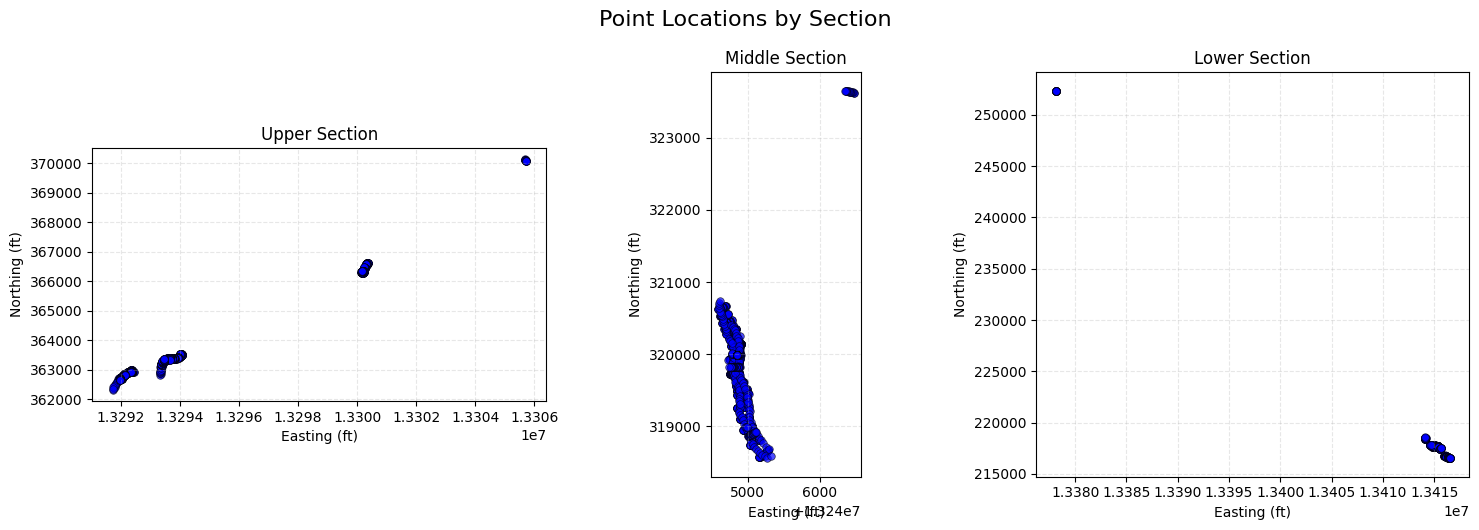

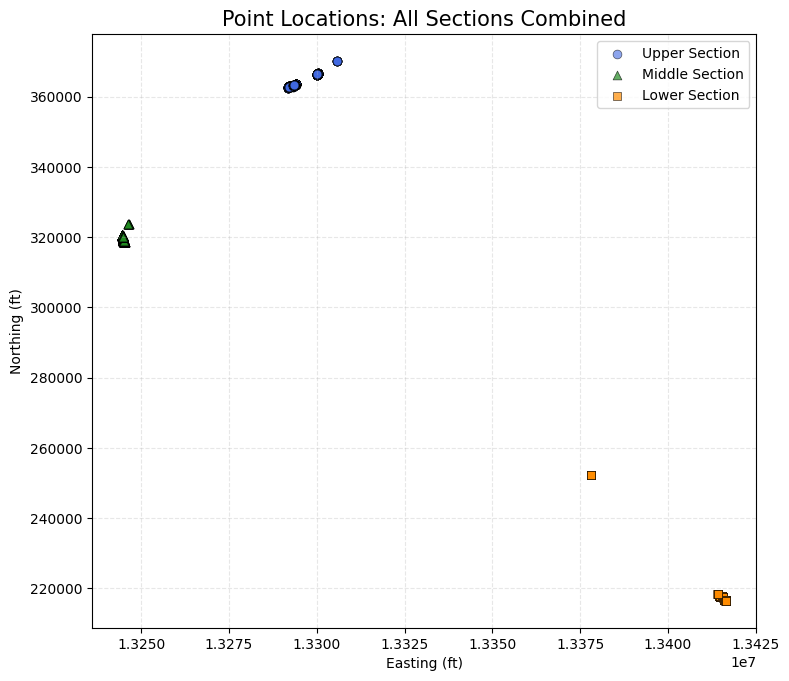

In [46]:
### 7) Visualize the data GeoJSONs to ensure all sorting happened properly
# These GeoJSONs are written from the in-memory trimmed frames in the cell above.
# Re-run that cell (and the trim cell) if the point counts below do not match the trim output.

# Import the GeoJSON files
df_Upper = gpd.read_file("mapping/data_Upper.geojson")
df_Middle = gpd.read_file("mapping/data_Middle.geojson")
df_Lower = gpd.read_file("mapping/data_Lower.geojson")

# Create a figure with subplots for each section
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Simple geospatial plot: just show point locations for each section

section_info = [
    (df_Upper, "Upper Section", 0),
    (df_Middle, "Middle Section", 1),
    (df_Lower, "Lower Section", 2)
]

for gdf, title, idx in section_info:
    ax = axes[idx]
    gdf.plot(
        ax=ax,
        marker='o',
        color='blue',
        edgecolor='k',
        linewidth=0.5,
        alpha=0.7,
        markersize=30
    )
    ax.set_title(title)
    ax.set_xlabel('Easting (ft)')
    ax.set_ylabel('Northing (ft)')
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.suptitle("Point Locations by Section", fontsize=16, y=1.05)
plt.show()
       
# Plot all points from the three GeoJSON files on top of one another in a single plot

fig, ax = plt.subplots(figsize=(8, 8))

df_Upper.plot(
    ax=ax,
    marker='o',
    color='royalblue',
    edgecolor='k',
    linewidth=0.5,
    alpha=0.6,
    markersize=40,
    label='Upper Section'
)
df_Middle.plot(
    ax=ax,
    marker='^',
    color='forestgreen',
    edgecolor='k',
    linewidth=0.5,
    alpha=0.7,
    markersize=40,
    label='Middle Section'
)
df_Lower.plot(
    ax=ax,
    marker='s',
    color='darkorange',
    edgecolor='k',
    linewidth=0.5,
    alpha=0.7,
    markersize=40,
    label='Lower Section'
)

ax.set_title("Point Locations: All Sections Combined", fontsize=15)
ax.set_xlabel('Easting (ft)')
ax.set_ylabel('Northing (ft)')
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [47]:
### Make the river stem a single object
# the clipped centerline is a branched network (main river + tributaries + island
# loops), and shapely's project() on a disconnected MultiLineString accumulates part lengths in
# arbitrary order, which corrupts downstream distances. 
# To fix it, build_main_stem() below merges the network into ONE continuous
# LineString: it starts from the branch nearest to the most data points and extends through
# junctions, preferring branches that carry data points (tie-break: longer branch). All
# projections (sign, along-line distance) are then done against this single main stem.

target_crs = "ESRI:102690"

# Load the full centerline once and convert to the working CRS (State Plane MI South, feet)
centerline_full = gpd.read_file("mapping/Huron_RiverSystem.geojson")
print(f"Centerline loaded: {len(centerline_full)} features, CRS {centerline_full.crs}")
centerline_full = centerline_full.to_crs(target_crs)

def build_main_stem(line_union, points, tol=1.0):
    """Merge a (possibly branched) centerline network into a single continuous LineString.
    Starts from the merged part nearest to the most data points, then extends the chain through
    junctions in both directions, preferring the branch with the most data points
    (tie-break: longer branch). `tol` is the snapping tolerance (ft) for matching endpoints."""
    merged = linemerge(line_union) if line_union.geom_type == 'MultiLineString' else line_union
    if merged.geom_type == 'LineString':
        return merged
    parts = list(merged.geoms)
    
    # Count how many data points are nearest to each part
    counts = [0] * len(parts)
    for pt in points:
        if pt is None or pt.is_empty:
            continue
        dists = [pt.distance(p) for p in parts]
        counts[int(np.argmin(dists))] += 1
    
    def close(a, b):
        return abs(a[0] - b[0]) <= tol and abs(a[1] - b[1]) <= tol
    
    seed = int(np.argmax(counts))
    used = {seed}
    chain = [list(parts[seed].coords)]  # ordered list of coordinate lists
    
    def find_next(node):
        """Best unused part touching `node`: most data points, then longest."""
        best_key, best_j = None, None
        for j, p in enumerate(parts):
            if j in used:
                continue
            coords = list(p.coords)
            if close(coords[0], node) or close(coords[-1], node):
                key = (counts[j], p.length)
                if best_key is None or key > best_key:
                    best_key, best_j = key, j
        return best_j
    
    # Extend forward from the end of the chain
    while True:
        node = chain[-1][-1]
        j = find_next(node)
        if j is None:
            break
        used.add(j)
        coords = list(parts[j].coords)
        if close(coords[-1], node):
            coords.reverse()
        chain.append(coords)
    # Extend backward from the start of the chain
    while True:
        node = chain[0][0]
        j = find_next(node)
        if j is None:
            break
        used.add(j)
        coords = list(parts[j].coords)
        if close(coords[0], node):
            coords.reverse()
        chain.insert(0, coords)
    
    stem_coords = []
    for coords in chain:
        stem_coords.extend(coords[1:] if stem_coords else coords)
    return LineString(stem_coords)

Centerline loaded: 58 features, CRS EPSG:4269


In [48]:
### 6) Distance to Centerline + Downstream Distance Calculation
# Computes, for every point in mapping/data_{Section}.geojson:
#   - distance_to_centerline: signed distance to the river centerline
#       (negative = left of centerline, positive = right, same convention as the old gpModel cell)
#   - dist_along_centerline: absolute projected distance along the section's main-stem centerline.
#       Kept so the downstream reference point can be recovered from the data files alone
#       (reference = dist_along_centerline - downstream_dist for any row), e.g. for translating
#       model results back to coordinates via main_stem.interpolate(reference + downstream_dist)
#   - downstream_dist: dist_along_centerline minus the reference distance, where the reference
#       is the upstream-most projected point among points within 150 ft of the centerline
#       (matching the outlier filter applied in the gpModel notebooks)

def distances_to_line(points, line):
    """For each shapely Point, return (signed distance to `line`, projected distance along `line`).
    Signed distance is negative on the left of the line, positive on the right."""
    eps = 1.0  # feet on either side of the projected point, used to get the local tangent
    line_length = line.length
    signed = np.empty(len(points))
    along = np.empty(len(points))
    for i, point in enumerate(points):
        # Rows with missing Easting/Northing have no geometry; give them NaN
        # (they are then removed by the 150 ft outlier filter in the gpModel notebooks)
        if point is None or point.is_empty:
            signed[i] = np.nan
            along[i] = np.nan
            continue
        distance = point.distance(line)
        # Locate the nearest position along the line, then take a short local tangent
        d_along = line.project(point)
        p1 = line.interpolate(max(d_along - eps, 0))
        p2 = line.interpolate(min(d_along + eps, line_length))
        # Cross product of tangent vector with vector to the point determines the side
        cross = (p2.x - p1.x) * (point.y - p1.y) - (p2.y - p1.y) * (point.x - p1.x)
        signed[i] = -distance if cross > 0 else distance
        along[i] = d_along
    return signed, along

for section_name in sections:
    # Use the in-memory gdf that was just plotted; fall back to disk if this cell is run alone
    if 'section_gdfs' in globals() and section_name in section_gdfs:
        gdf = section_gdfs[section_name].copy()
    else:
        gdf = gpd.read_file(f"mapping/data_{section_name}.geojson")
    
    # Clip the centerline to this section's bounding box (500 ft buffer) to keep it small
    minx, miny, maxx, maxy = gdf.total_bounds
    bbox = box(minx - 500, miny - 500, maxx + 500, maxy + 500)
    section_centerline = centerline_full[centerline_full.geometry.intersects(bbox)]
    
    # Merge the branched network into one continuous main-stem LineString
    centerline_union = build_main_stem(section_centerline.geometry.union_all(), gdf.geometry.values)

    # Calculate signed distance to centerline and projected distance along it (one pass)
    signed_dists, along_dists = distances_to_line(gdf.geometry.values, centerline_union)
    gdf['distance_to_centerline'] = signed_dists
    gdf['dist_along_centerline'] = along_dists
    
    # Downstream distance: relative to the upstream-most projected point, considering only
    # points that will survive the 150 ft centerline-distance outlier filter in the gpModel
    # notebooks (so an off-river outlier can't shift the reference)
    valid_reference = np.abs(signed_dists) <= 150
    reference_distance = np.nanmin(along_dists[valid_reference])
    gdf['downstream_dist'] = along_dists - reference_distance
    
    print(f"\nSection: {section_name} ({len(gdf)} points, "
          f"{len(section_centerline)} centerline features in bbox, "
          f"main stem length {centerline_union.length:.0f} ft)")
    print(f"  Points with no geometry (NaN distance): {gdf['distance_to_centerline'].isna().sum()}")
    print(f"  Min distance:  {gdf['distance_to_centerline'].min():.2f} ft")
    print(f"  Max distance:  {gdf['distance_to_centerline'].max():.2f} ft")
    print(f"  Mean distance: {gdf['distance_to_centerline'].mean():.2f} ft")
    print(f"  Downstream reference distance: {reference_distance:.2f} ft")
    print(f"  Downstream range (within 150 ft of centerline): "
          f"{gdf.loc[valid_reference, 'downstream_dist'].min():.1f} to "
          f"{gdf.loc[valid_reference, 'downstream_dist'].max():.1f} ft")
    
    # Save the distance column back into the trimmed CSV (all original columns, no geometry)
    csv_path = os.path.join("sorted_data", f"complete_data_{section_name}.csv")
    pd.DataFrame(gdf.drop(columns='geometry')).to_csv(csv_path, index=False)
    print(f"  Updated {csv_path}")
    
    # Re-save the GeoJSON so it stays in sync with the CSV
    geojson_path = os.path.join("mapping", f"data_{section_name}.geojson")
    gdf.to_file(geojson_path, driver='GeoJSON')
    print(f"  Updated {geojson_path}")
    
    # Save the merged main-stem centerline (shapely LineString must be wrapped in a GeoDataFrame).
    # Used later to invert model coordinates, e.g. in modelVisualizations_Middle.ipynb:
    #   centerline = gpd.read_file("mapping/centerline_union_Middle.geojson")
    #   centerline_geom = centerline.geometry.iloc[0]
    centerline_path = os.path.join("mapping", f"centerline_union_{section_name}.geojson")
    gpd.GeoDataFrame(
        geometry=[centerline_union],
        crs=gdf.crs,
    ).to_file(centerline_path, driver='GeoJSON')
    print(f"  Updated {centerline_path}")


Section: Upper (741 points, 4 centerline features in bbox, main stem length 44906 ft)
  Points with no geometry (NaN distance): 0
  Min distance:  -76.81 ft
  Max distance:  48.22 ft
  Mean distance: -13.17 ft
  Downstream reference distance: 5752.83 ft
  Downstream range (within 150 ft of centerline): 0.0 to 25597.0 ft
  Updated sorted_data\complete_data_Upper.csv
  Updated mapping\data_Upper.geojson


Skipping field Collection Time: unsupported OGR type: 10


  Updated mapping\centerline_union_Upper.geojson

Section: Middle (1377 points, 2 centerline features in bbox, main stem length 32698 ft)
  Points with no geometry (NaN distance): 3
  Min distance:  -117.95 ft
  Max distance:  121.89 ft
  Mean distance: -12.16 ft
  Downstream reference distance: 11045.64 ft
  Downstream range (within 150 ft of centerline): 0.0 to 6191.3 ft
  Updated sorted_data\complete_data_Middle.csv


Skipping field Collection Time: unsupported OGR type: 10


  Updated mapping\data_Middle.geojson
  Updated mapping\centerline_union_Middle.geojson

Section: Lower (417 points, 3 centerline features in bbox, main stem length 153501 ft)
  Points with no geometry (NaN distance): 2
  Min distance:  -201.86 ft
  Max distance:  93.39 ft
  Mean distance: -7.54 ft
  Downstream reference distance: 99494.05 ft
  Downstream range (within 150 ft of centerline): 0.0 to 3498.9 ft
  Updated sorted_data\complete_data_Lower.csv
  Updated mapping\data_Lower.geojson
  Updated mapping\centerline_union_Lower.geojson
